# Day 26 — Customer Analysis
Project 1 | Retail Sales & Customer Performance Analysis

Objective: Who are the company’s most valuable customers? Customer_Name is a proxy for Customer_ID; identical names may represent different people. October 2026 only.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display
sns.set_theme(style='whitegrid')
Path('charts').mkdir(exist_ok=True)
df = pd.read_csv('transformed_retail_sales.csv')
display(df.head())
print(df.shape)

,Order_ID,Order_Date,Customer_Name,City,Category,Product,Quantity,Unit_Price,Sales,Customer_Rating,Customer_Rating_Was_Imputed,Year,Month,Month_Name,Quarter,Profit_Margin,Order_Value,Customer_Total_Spending,Customer_Segment,Sales_Category,Customer_Order_Count,Customer_Type,Product_Total_Sales,Product_Performance,Order_Size,Day_Name,Is_Weekend
0,ORD001,2026-10-02,Rahul,Mumbai,Clothing,T-Shirt,2,650,1300,5.0,False,2026,10,October,4,NaN,1300,13350,Medium Value,Medium,5,Repeat,14950,Low,Small,Friday,False
1,ORD002,2026-10-03,Neha,Nagpur,Grocery,Rice,3,320,960,3.0,False,2026,10,October,4,NaN,960,10700,Medium Value,Low,5,Repeat,6720,Low,Medium,Saturday,True
2,ORD003,2026-10-04,Vikram,Nashik,Home,Lamp,4,1100,4400,4.0,False,2026,10,October,4,NaN,4400,13350,Medium Value,High,5,Repeat,24200,High,Medium,Sunday,True
3,ORD004,2026-10-05,Priya,Pune,Electronics,Headphones,5,1500,7500,5.0,False,2026,10,October,4,NaN,7500,17780,High Value,High,5,Repeat,36000,High,Large,Monday,False
4,ORD005,2026-10-06,Arjun,Pune,Clothing,T-Shirt,1,650,650,4.0,False,2026,10,October,4,NaN,650,12450,Medium Value,Low,5,Repeat,14950,Low,Small,Tuesday,False


(30, 27)


## Task 1 — Customer Revenue
Group sales by customer name.

In [2]:
customer_sales = df.groupby('Customer_Name')['Sales'].sum().sort_values(ascending=False)
display(customer_sales.to_frame('Revenue'))

,Revenue
Customer_Name,
Priya,17780
Asha,14240
Vikram,13350
Rahul,13350
Arjun,12450
Neha,10700


## Task 2 — Top Customers
Only six names exist; both lists show all available customers.

In [3]:
top10 = customer_sales.head(10)
top20 = customer_sales.head(20)
display(top10.to_frame('Top 10 revenue'))
display(top20.to_frame('Top 20 revenue'))
top10.to_csv('top_10_customers.csv', header=['Revenue'])
top20.to_csv('top_20_customers.csv', header=['Revenue'])

,Top 10 revenue
Customer_Name,
Priya,17780
Asha,14240
Vikram,13350
Rahul,13350
Arjun,12450
Neha,10700


,Top 20 revenue
Customer_Name,
Priya,17780
Asha,14240
Vikram,13350
Rahul,13350
Arjun,12450
Neha,10700


## Task 3 — Average Customer Spending
Total customer sales divided by number of customers. This is distinct from average order value.

In [4]:
total = customer_sales.sum()
print('Total revenue:', total)
print('Average customer spending:', total / len(customer_sales))
print('Average order value:', total / df.Order_ID.nunique())

Total revenue: 81870
Average customer spending: 13645.0
Average order value: 2729.0


## Task 4 — Repeat Customers
Count distinct order IDs; repeat means more than one order.

In [5]:
orders_per_customer = df.groupby('Customer_Name')['Order_ID'].nunique()
summary = customer_sales.to_frame('Revenue').join(orders_per_customer.rename('Orders'))
summary['Average_Order_Value'] = summary.Revenue / summary.Orders
summary['Customer_Type'] = summary.Orders.map(lambda x: 'Repeat' if x > 1 else 'One-time')
display(summary)
print('Repeat rate:', summary.Customer_Type.eq('Repeat').mean()*100)

,Revenue,Orders,Average_Order_Value,Customer_Type
Customer_Name,,,,
Priya,17780,5,3556.0,Repeat
Asha,14240,5,2848.0,Repeat
Vikram,13350,5,2670.0,Repeat
Rahul,13350,5,2670.0,Repeat
Arjun,12450,5,2490.0,Repeat
Neha,10700,5,2140.0,Repeat


Repeat rate: 100.0


## Task 5 — Customer Contribution
Each customer’s revenue divided by total revenue × 100.

In [6]:
summary['Contribution_Pct'] = summary.Revenue / total * 100
display(summary[['Revenue','Contribution_Pct']])

,Revenue,Contribution_Pct
Customer_Name,,
Priya,17780,21.717357
Asha,14240,17.393429
Vikram,13350,16.306339
Rahul,13350,16.306339
Arjun,12450,15.207036
Neha,10700,13.069500


## Task 6 — Customer Segments
Day 24 thresholds: High Value >= INR 15,000; Medium Value >= INR 10,000 and < INR 15,000; Low Value < INR 10,000. These are project-defined, not industry benchmarks.

In [7]:
summary['Segment'] = summary.Revenue.map(lambda x: 'High Value' if x >= 15000 else ('Medium Value' if x >= 10000 else 'Low Value'))
segments = summary.groupby('Segment').agg(Customers=('Revenue','size'), Revenue=('Revenue','sum')).reindex(['High Value','Medium Value','Low Value'],fill_value=0)
repeat = summary.Customer_Type.value_counts().reindex(['Repeat','One-time'],fill_value=0)
display(summary)
display(segments)
summary.to_csv('customer_summary.csv')
segments.to_csv('customer_segments.csv')
repeat.to_csv('repeat_customers.csv',header=['Customers'])
assert summary.Revenue.sum() == df.Sales.sum()
assert abs(summary.Contribution_Pct.sum()-100)<1e-8
assert summary.Orders.sum() == df.Order_ID.nunique()
print('Validation passed')

,Revenue,Orders,Average_Order_Value,Customer_Type,Contribution_Pct,Segment
Customer_Name,,,,,,
Priya,17780,5,3556.0,Repeat,21.717357,High Value
Asha,14240,5,2848.0,Repeat,17.393429,Medium Value
Vikram,13350,5,2670.0,Repeat,16.306339,Medium Value
Rahul,13350,5,2670.0,Repeat,16.306339,Medium Value
Arjun,12450,5,2490.0,Repeat,15.207036,Medium Value
Neha,10700,5,2140.0,Repeat,13.069500,Medium Value


,Customers,Revenue
Segment,,
High Value,1,17780
Medium Value,5,64090
Low Value,0,0


Validation passed


## Task 7 — Visualizations

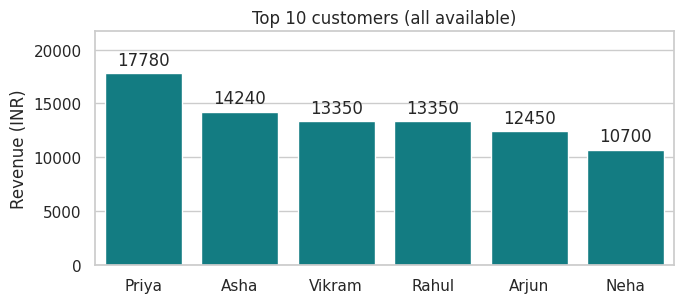

In [8]:
s = top10
fig, ax = plt.subplots(figsize=(7,3.2))
sns.barplot(x=s.index, y=s.values, color='#008C95', ax=ax)
ax.set(title='Top 10 customers (all available)', xlabel='', ylabel='Revenue (INR)')
ax.bar_label(ax.containers[0], fmt='%.2f' if 0 == 1 else '%.0f', padding=3)
ax.set_ylim(0,max(s.values)*1.22)
fig.tight_layout()
fig.savefig('charts/01_top_customers.png',dpi=160)
plt.show()
plt.close(fig)

**Interpretation:** Priya leads revenue; only six customer names are available.

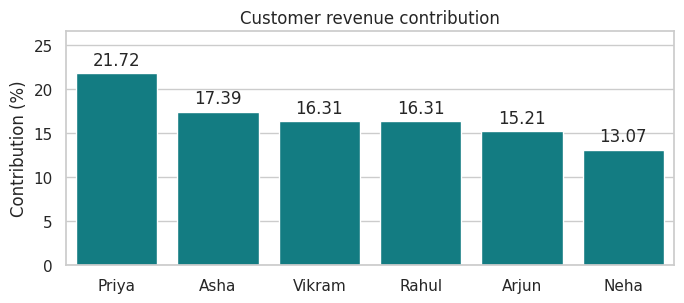

In [9]:
s = summary.Contribution_Pct
fig, ax = plt.subplots(figsize=(7,3.2))
sns.barplot(x=s.index, y=s.values, color='#008C95', ax=ax)
ax.set(title='Customer revenue contribution', xlabel='', ylabel='Contribution (%)')
ax.bar_label(ax.containers[0], fmt='%.2f' if 1 == 1 else '%.0f', padding=3)
ax.set_ylim(0,max(s.values)*1.22)
fig.tight_layout()
fig.savefig('charts/02_contribution.png',dpi=160)
plt.show()
plt.close(fig)

**Interpretation:** Priya contributes the largest share; monitor concentration.

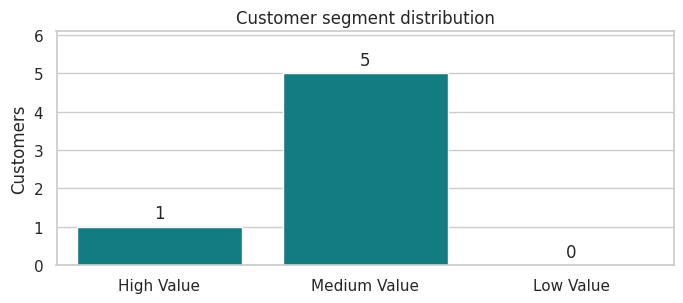

In [10]:
s = segments.Customers
fig, ax = plt.subplots(figsize=(7,3.2))
sns.barplot(x=s.index, y=s.values, color='#008C95', ax=ax)
ax.set(title='Customer segment distribution', xlabel='', ylabel='Customers')
ax.bar_label(ax.containers[0], fmt='%.2f' if 2 == 1 else '%.0f', padding=3)
ax.set_ylim(0,max(s.values)*1.22)
fig.tight_layout()
fig.savefig('charts/03_segments.png',dpi=160)
plt.show()
plt.close(fig)

**Interpretation:** One high-value and five medium-value customers; no low-value customers.

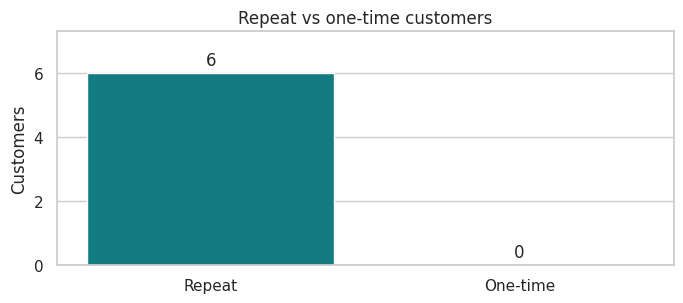

In [11]:
s = repeat
fig, ax = plt.subplots(figsize=(7,3.2))
sns.barplot(x=s.index, y=s.values, color='#008C95', ax=ax)
ax.set(title='Repeat vs one-time customers', xlabel='', ylabel='Customers')
ax.bar_label(ax.containers[0], fmt='%.2f' if 3 == 1 else '%.0f', padding=3)
ax.set_ylim(0,max(s.values)*1.22)
fig.tight_layout()
fig.savefig('charts/04_repeat.png',dpi=160)
plt.show()
plt.close(fig)

**Interpretation:** All six names have multiple orders in October; this does not establish long-term retention.

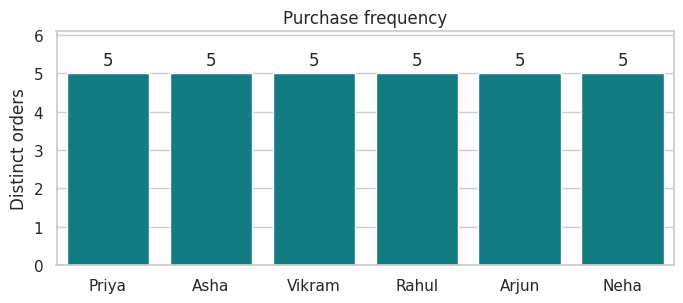

In [12]:
s = summary.Orders
fig, ax = plt.subplots(figsize=(7,3.2))
sns.barplot(x=s.index, y=s.values, color='#008C95', ax=ax)
ax.set(title='Purchase frequency', xlabel='', ylabel='Distinct orders')
ax.bar_label(ax.containers[0], fmt='%.2f' if 4 == 1 else '%.0f', padding=3)
ax.set_ylim(0,max(s.values)*1.22)
fig.tight_layout()
fig.savefig('charts/05_frequency.png',dpi=160)
plt.show()
plt.close(fig)

**Interpretation:** Compare order counts to identify frequent buyers; frequency alone does not measure value.

## Recommendations and limitations
Prioritize high-value customers for retention, test offers for medium-value customers, and collect stable customer IDs and more months of history. Do not infer lifetime value, churn or profit from this dataset.